Face recognition and Attendance System

An automated facial recognition system built to identify known students in classroom images and log attendance to a local CSV file

Consent and Privacy Notice

Explicit Consent: All student portrait images in the training and testing datasets are collected with explicit user consent.
No Public Distribution: Real student facial photographs and personal biometric assets are kept strictly private and will never be shared publicly or published to online repositories.
Academic & Ethical Standards: This project is developed solely for educational and research evaluation under privacy-compliant data guidelines.

Data Handling and Scrunity Rules

Local & Offline Processing: All facial detection, embedding extraction, and attendance logging operations are performed 100% locally and offline on the host computer.
Repository Isolation (.gitignore):
The local dataset folder containing student images (e.g., dataset/ or lfw/) is strictly excluded from version control via .gitignore .
No raw image files or private student photos are committed or pushed to GitHub.
Log Handling: Attendance results are generated locally into attendance.csv containing only Name, Date, and Time stamps.

Tech Stack & Dependencies

Python 3.x
InsightFace: Pretrained face-analysis models for face detection and facial embedding extraction, using the buffalo_l model pack.
ONNX Runtime: Executes the pretrained InsightFace models for face detection and recognition.
OpenCV (cv2): Image loading and computer vision operations
Pandas: Data handling and attendance CSV management
Matplotlib: Visualizing Exploratory Data Analysis (EDA) charts

In [3]:
import cv2
import numpy as np
import pandas as pd
from insightface.app import FaceAnalysis

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
app = FaceAnalysis(name="buffalo_l")
app.prepare(ctx_id=-1, det_size=(320, 320))

print("Face detection model loaded successfully")

Face detection model loaded successfully


In [11]:
import cv2

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not cap.isOpened():
    print("Could not open webcam")
else:
    print("Webcam opened successfully")
    

Webcam opened successfully


c:\coding\Face recognition project\.venv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Number of faces detected: 1


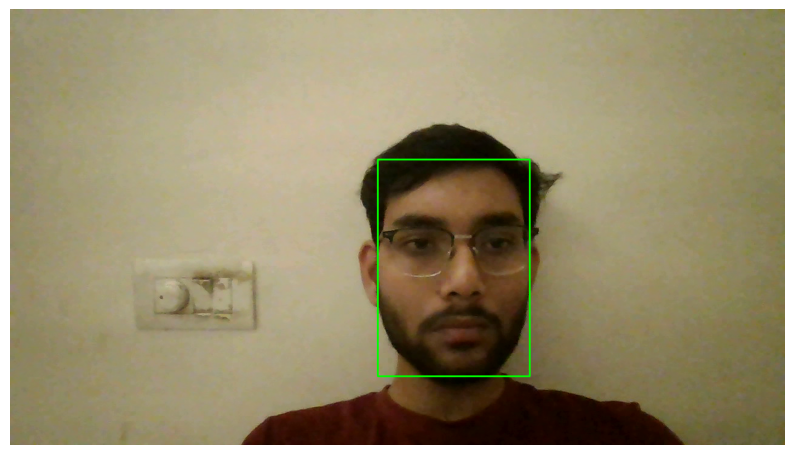

In [12]:
ret, frame = cap.read()

if ret:
    faces = app.get(frame)
    print("Number of faces detected:", len(faces))

    for face in faces:
        x1, y1, x2, y2 = face.bbox.astype(int)
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    import matplotlib.pyplot as plt
    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()
else:
    print("Could not capture a frame")

In [14]:
cap.release()
print("Webcam released")

Webcam released


In [8]:
if len(faces) > 0:
    embedding = faces[0].normed_embedding

    print("Embedding shape:", embedding.shape)
    print("First 10 values:", embedding[:10])
else:
    print("No face detected. Try again.")

Embedding shape: (512,)
First 10 values: [ 0.07259217  0.01717201  0.03596975  0.0235928  -0.02522175  0.01088219
  0.04888703 -0.04568579 -0.01357218  0.05510253]


In [13]:
import numpy as np
import pickle
import os

ret, frame = cap.read()

if ret:
    faces = app.get(frame)

    if len(faces) > 0:
        name = input("Enter student name: ")

        embedding = faces[0].normed_embedding

        os.makedirs("student_data", exist_ok=True)

        file_path = os.path.join("student_data", "students.pkl")

        if os.path.exists(file_path):
            with open(file_path, "rb") as file:
                students = pickle.load(file)
        else:
            students = {}

        students[name] = embedding

        with open(file_path, "wb") as file:
            pickle.dump(students, file)

        print("Registered successfully:", name)
    else:
        print("No face detected. Try again.")
else:
    print("Could not capture webcam frame.")

Registered successfully: Uday MS24203
